## Interval Analysis

In [18]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [19]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [20]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 2.012
Epoch 2/15, Loss: 1.729
Epoch 3/15, Loss: 1.627
Epoch 4/15, Loss: 1.596
Epoch 5/15, Loss: 1.582
Epoch 6/15, Loss: 1.572
Epoch 7/15, Loss: 1.566
Epoch 8/15, Loss: 1.561
Epoch 9/15, Loss: 1.557
Epoch 10/15, Loss: 1.553
Epoch 11/15, Loss: 1.550
Epoch 12/15, Loss: 1.547
Epoch 13/15, Loss: 1.545
Epoch 14/15, Loss: 1.542
Epoch 15/15, Loss: 1.540
Accuracy on images: 93.43


In [21]:
def interval_linear(lower, upper, layer):
    W = layer.weight
    b = layer.bias
    W_pos = torch.clamp(W, min=0)
    W_neg = torch.clamp(W, max=0)

    new_lower = (F.linear(lower, W_pos, b) + F.linear(upper, W_neg))
    new_upper = (F.linear(upper, W_pos, b) + F.linear(lower, W_neg))

    return new_lower, new_upper

### Write the interval analysis for the simple model

In [22]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation
@torch.no_grad()
def certify_batch(model, images, labels, eps):
    lower = torch.clamp(images - eps, 0, 1)
    upper = torch.clamp(images + eps, 0, 1)

    norm = model[0]
    lower = norm(lower).flatten(1)
    upper = norm(upper).flatten(1)
    net = model[1]
    lower, upper = interval_linear(lower, upper, net.fc)
    lower = F.relu(lower)
    upper = F.relu(upper)

    W = net.fc2.weight
    b = net.fc2.bias
    W_diff = W[labels][:,None,:]-W[None,:,:]
    b_diff = b[labels][:,None]-b[None,:]
    W_pos = W_diff.clamp(min=0)
    W_neg = W_diff.clamp(max=0)

    diff_lower = (torch.bmm(W_pos, lower.unsqueeze(-1)).squeeze(-1)+torch.bmm(W_neg, upper.unsqueeze(-1)).squeeze(-1)+b_diff)

    classes = torch.arange(W.shape[0], device=labels.device)
    mask = classes.unsqueeze(0) != labels.unsqueeze(1)

    verified = ((diff_lower >= 0) | ~mask).all(dim=1)

    return verified

In [23]:
@torch.no_grad()
def evaluate_robustness(model, eps):
    model.eval()
    verified_count = 0
    total = 0

    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        verified = certify_batch(model, images, labels, eps)

        verified_count += verified.sum().item()
        total += labels.size(0)

    return 100 * verified_count / total

eps_values = np.linspace(0.01, 0.1, 10)

verified_accuracies = []
for eps in eps_values:
    acc = evaluate_robustness(model, float(eps))
    verified_accuracies.append(acc)
    print(f"Epsilon: {eps:.2f}, Verified Accuracy: {acc:.2f}%")

Epsilon: 0.01, Verified Accuracy: 70.55%
Epsilon: 0.02, Verified Accuracy: 23.68%
Epsilon: 0.03, Verified Accuracy: 4.56%
Epsilon: 0.04, Verified Accuracy: 0.58%
Epsilon: 0.05, Verified Accuracy: 0.02%
Epsilon: 0.06, Verified Accuracy: 0.00%
Epsilon: 0.07, Verified Accuracy: 0.00%
Epsilon: 0.08, Verified Accuracy: 0.00%
Epsilon: 0.09, Verified Accuracy: 0.00%
Epsilon: 0.10, Verified Accuracy: 0.00%


**Below is for reporting the results**

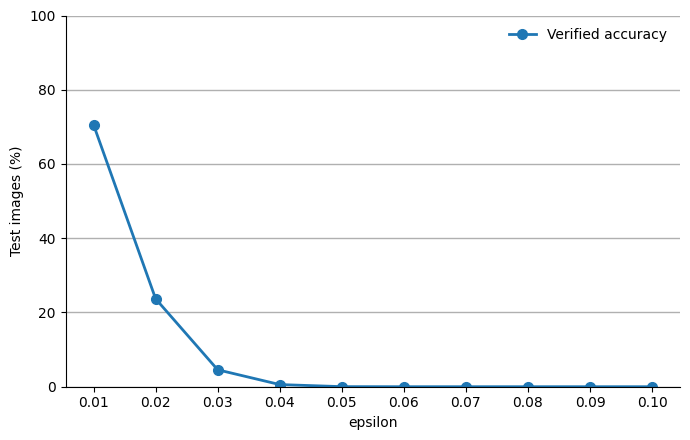

In [24]:
figure, axis = plt.subplots(figsize=(7, 4.5))

axis.plot(eps_values, verified_accuracies, linewidth=2, marker="o",markersize=7, label="Verified accuracy")

axis.set_xticks(eps_values)
axis.set_xticklabels([f"{eps:.2f}" for eps in eps_values])
axis.set_xlabel(r"epsilon")
axis.set_ylabel("Test images (%)")
axis.set_ylim(0, 100)
axis.grid(axis="y", linewidth=1)
axis.spines["top"].set_visible(False)
axis.spines["right"].set_visible(False)
axis.legend(frameon=False)

plt.tight_layout()
plt.show()

### Observations
- Clean accuracy is 93.43% after 15 epochs.
- Verified accuracy drops quickly, and tt is monotonically decreasing, as expected, since a larger ball contains the smaller one.
- The analysis is sound, so every verified image should be robust, but a failed check does not mean an adversarial example exists.
- Every neuron is bounded independently, so correlations between neurons that depend on the same pixels are lost. The width of each bound grows with the sum of absolute weights at every layer, and as epsilon grows more hidden ReLUs become unstable (their pre-activation interval contains 0), in which case Box outputs [0, u].
- Interval analysis is very cheap, the whole test set is analyzed in very quick time, compared to a complete method such as MILP.